# 11 — Heat Accessibility and Mobility Link

This notebook compares modeled heat-conditioned accessibility loss with observed hot-day mobility reduction across Sevilla districts.

The objective is exploratory:

- aggregate modeled accessibility loss spatially;
- align it with district-level observed mobility change;
- test whether areas with larger modeled thermal-accessibility penalties also show larger mobility reductions on hot days.

The analysis is associative and does not establish causality.

In [1]:
from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

ACCESSIBILITY_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "accessibility"
)

MOBILE_PROCESSED = (
    PROJECT_ROOT
    / "data"
    / "mobile"
    / "processed"
)

MOBILE_INTERIM = (
    PROJECT_ROOT
    / "data"
    / "mobile"
    / "interim"
)

In [2]:
mobility = pd.read_parquet(
    MOBILE_PROCESSED
    / "sevilla_district_hot_reference_mobility.parquet"
)

mobility

,id_origin,district_name,district_population,reference,hot,change_pct
0,4109105,Sevilla distrito 05,68916.0,199057.88275,161321.5184,-18.957483
1,4109103,Sevilla distrito 03,50394.0,140221.46800,114626.1748,-18.253477
2,4109101,Sevilla distrito 01,54914.0,178271.47150,145845.4648,-18.189117
3,4109110,Sevilla distrito 10,41589.0,106950.90175,88074.7310,-17.649380
4,4109111,Sevilla distrito 11,25033.0,60734.93050,50959.6002,-16.095071
5,4109106,Sevilla distrito 06,46253.0,123400.16850,103737.8264,-15.933805
6,4109108,Sevilla distrito 08,59239.0,181766.99075,155472.0102,-14.466312
7,4109107,Sevilla distrito 07,72030.0,157761.96925,137393.7560,-12.910725
8,4109102,Sevilla distrito 02,73367.0,153318.06200,133963.0940,-12.624063
9,4109109,Sevilla distrito 09,104255.0,231502.02550,202560.8898,-12.501461


In [3]:
access = pd.read_csv(
    ACCESSIBILITY_DIR
    / "origin_accessibility_lambda_005.csv"
)

print(access.shape)
print(access.columns.tolist())

access.head()

(49, 5)
['origin', 'normal_access', 'thermal_access', 'access_loss', 'access_loss_pct']


,origin,normal_access,thermal_access,access_loss,access_loss_pct
0,12705553216,27,16,11,40.740741
1,10215553612,40,19,21,52.500000
2,2448671721,29,19,10,34.482759
3,5959692077,18,10,8,44.444444
4,13031291689,31,13,18,58.064516


In [4]:
zones = gpd.read_file(
    MOBILE_INTERIM
    / "sevilla_districts_v2.gpkg"
)

print(zones.crs)
zones[
    [
        "id",
        "name",
        "population"
    ]
]

EPSG:3042


,id,name,population
0,4109101,Sevilla distrito 01,54914.0
1,4109102,Sevilla distrito 02,73367.0
2,4109103,Sevilla distrito 03,50394.0
3,4109104,Sevilla distrito 04,88244.0
4,4109105,Sevilla distrito 05,68916.0
5,4109106,Sevilla distrito 06,46253.0
6,4109107,Sevilla distrito 07,72030.0
7,4109108,Sevilla distrito 08,59239.0
8,4109109,Sevilla distrito 09,104255.0
9,4109110,Sevilla distrito 10,41589.0


In [5]:
access.columns.tolist()

['origin', 'normal_access', 'thermal_access', 'access_loss', 'access_loss_pct']

In [6]:
print(access.columns.tolist())
access.head()


['origin', 'normal_access', 'thermal_access', 'access_loss', 'access_loss_pct']


,origin,normal_access,thermal_access,access_loss,access_loss_pct
0,12705553216,27,16,11,40.740741
1,10215553612,40,19,21,52.500000
2,2448671721,29,19,10,34.482759
3,5959692077,18,10,8,44.444444
4,13031291689,31,13,18,58.064516


In [7]:
import osmnx as ox

THERMAL_GRAPH = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "sevilla_walk_thermal.graphml"
)

G = ox.load_graphml(THERMAL_GRAPH)

print(
    "Graph:",
    len(G.nodes),
    "nodes,",
    len(G.edges),
    "edges"
)
print("CRS:", G.graph["crs"])

Graph: 1630 nodes, 4612 edges
CRS: EPSG:25830


In [8]:
nodes, edges = ox.graph_to_gdfs(G)

nodes = nodes.reset_index()

print(nodes.columns.tolist())
nodes.head()

['osmid', 'y', 'x', 'street_count', 'highway', 'ref', 'geometry']


,osmid,y,x,street_count,highway,ref,geometry
0,304499541,4.141999e+06,237253.283395,4,traffic_signals,NaN,POINT (237253.283 4141998.882)
1,1957097246,4.142026e+06,237253.690044,3,NaN,NaN,POINT (237253.69 4142026.442)
2,2528424748,4.141995e+06,237369.340641,3,NaN,NaN,POINT (237369.341 4141994.618)
3,421923023,4.141996e+06,237137.989463,3,NaN,NaN,POINT (237137.989 4141996.425)
4,12111584428,4.141986e+06,237253.016431,4,crossing,NaN,POINT (237253.016 4141986.46)


In [9]:
nodes["osmid"] = nodes["osmid"].astype(str)
access["origin"] = access["origin"].astype(str)

access_origins = nodes[
    nodes["osmid"].isin(access["origin"])
].copy()

print(
    "Accessibility origins found:",
    len(access_origins),
    "/",
    len(access)
)

Accessibility origins found: 49 / 49


In [11]:
access_origins = access_origins.merge(
    access,
    left_on="osmid",
    right_on="origin",
    how="inner"
)

access_origins[
    [
        "origin",
        "normal_access",
        "thermal_access",
        "access_loss_pct",
        "geometry"
    ]
].head()

,origin,normal_access,thermal_access,access_loss_pct,geometry
0,3859840024,43,24,44.186047,POINT (237989.2 4141956.241)
1,1968780510,15,7,53.333333,POINT (239276.578 4143246.392)
2,10215553612,40,19,52.500000,POINT (237509.555 4142701.726)
3,12146727285,39,16,58.974359,POINT (238103.421 4142889.625)
4,405557071,27,13,51.851852,POINT (237260.237 4142272.7)


In [12]:
zones_graph = zones.to_crs(
    access_origins.crs
)

print("Origins CRS:", access_origins.crs)
print("Zones CRS:", zones_graph.crs)

Origins CRS: EPSG:25830
Zones CRS: EPSG:25830


In [13]:
origins_district = gpd.sjoin(
    access_origins,
    zones_graph[
        [
            "id",
            "name",
            "geometry"
        ]
    ],
    how="left",
    predicate="within"
)

origins_district[
    [
        "origin",
        "name",
        "access_loss_pct"
    ]
].head()

,origin,name,access_loss_pct
0,3859840024,Sevilla distrito 03,44.186047
1,1968780510,Sevilla distrito 08,53.333333
2,10215553612,Sevilla distrito 08,52.500000
3,12146727285,Sevilla distrito 08,58.974359
4,405557071,Sevilla distrito 08,51.851852


In [14]:
print(
    "Origins assigned to districts:",
    origins_district["id"].notna().sum(),
    "/",
    len(origins_district)
)

print(
    origins_district["name"]
    .value_counts(dropna=False)
)

Origins assigned to districts: 49 / 49
name
Sevilla distrito 08    38
Sevilla distrito 04     9
Sevilla distrito 03     2
Name: count, dtype: int64


In [16]:
district_access = (
    origins_district
    .groupby(
        ["id", "name"],
        as_index=False
    )
    .agg(
        n_origins=("origin", "size"),
        mean_access_loss_pct=("access_loss_pct", "mean"),
        median_access_loss_pct=("access_loss_pct", "median"),
        mean_normal_access=("normal_access", "mean"),
        mean_thermal_access=("thermal_access", "mean")
    )
)

district_access

,id,name,n_origins,mean_access_loss_pct,median_access_loss_pct,mean_normal_access,mean_thermal_access
0,4109103,Sevilla distrito 03,2,52.975376,52.975376,38.500000,18.5
1,4109104,Sevilla distrito 04,9,45.348780,44.444444,18.666667,10.0
2,4109108,Sevilla distrito 08,38,52.972045,52.175926,27.500000,13.0


In [17]:
mobility["id_origin"] = mobility["id_origin"].astype(str)
district_access["id"] = district_access["id"].astype(str)

linked = district_access.merge(
    mobility[
        [
            "id_origin",
            "district_name",
            "change_pct"
        ]
    ],
    left_on="id",
    right_on="id_origin",
    how="left"
)

linked[
    [
        "name",
        "n_origins",
        "mean_access_loss_pct",
        "change_pct"
    ]
]

,name,n_origins,mean_access_loss_pct,change_pct
0,Sevilla distrito 03,2,52.975376,-18.253477
1,Sevilla distrito 04,9,45.348780,-9.976968
2,Sevilla distrito 08,38,52.972045,-14.466312


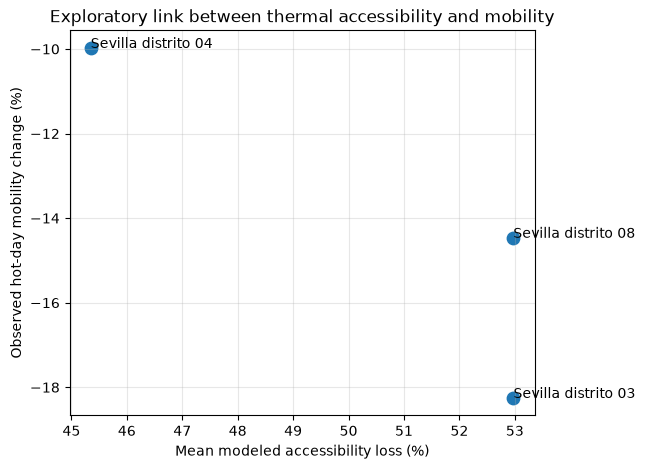

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    linked["mean_access_loss_pct"],
    linked["change_pct"],
    s=80
)

for _, row in linked.iterrows():
    ax.annotate(
        row["name"],
        (
            row["mean_access_loss_pct"],
            row["change_pct"]
        )
    )

ax.set_xlabel("Mean modeled accessibility loss (%)")
ax.set_ylabel("Observed hot-day mobility change (%)")
ax.set_title(
    "Exploratory link between thermal accessibility and mobility"
)

ax.grid(alpha=0.3)

plt.show()